# 🤖 Comprehensive Scikit-Learn Classifier Comparison & Hyperparameter Tuning Pipeline

This notebook demonstrates how to load a custom dataset from a CSV file, preprocess features, cross-evaluate multiple popular Scikit-learn algorithms, and perform automated **Hyperparameter Tuning** via `GridSearchCV` on the best performing model.

[Reference](https://share.google/aimode/3tJARxDU6hoZi39Xw)

[Random Forest versus Gradient Boosting](https://share.google/aimode/W2P2LrGJHtrXcueVk)

[Models that don't need scaling](https://share.google/aimode/ZwFe4mIbvlaKYkKui)

[Hyperparameter tuning](https://share.google/aimode/s8MTxLavGQNBXoaZ0)

[SpatiaLite blob to image](https://share.google/aimode/GHJcmvz5y4QjaueLw)

#### Important Note

After examining results from this notebook, I decided to use the Random Forest for further development. 
Unlike some of the models test here, RF does not require use of the StandardScaler. The saved model should
be retrained without StanadardScaler for my specific application.

In [1]:
import sqlite3
import io
import matplotlib.pyplot as plt
from shapely import wkt
from shapely.geometry import base

def wkt_str_to_image(wkt_string, title, output_path=None, show_image=True):
    """
    Parses the WKT geometry string, renders it visually, and outputs an image.
    Polygon geometries are expected to be supported. Other geometry types will be skipped with a message.
    """
    if not wkt_string:
        print("No geometry data provided. Skipping.")
        return
        
    geom = wkt.loads(wkt_string)
    if not geom.geom_type == 'Polygon':
        print('Geometry is not a Polygon. Skipping.')
        return
    
    # Set up matplotlib figure and axis
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Plot exterior ring
    x, y = geom.exterior.xy
    ax.plot(x, y, color='#6699cc', alpha=1.0, linewidth=2, solid_capstyle='round', zorder=2)
    ax.fill(x, y, color='#6699cc', alpha=0.3)
    # Plot any interior holes if they exist
    for interior in geom.interiors:
        ix, iy = interior.xy
        ax.plot(ix, iy, color='#ff3333', alpha=0.8, linewidth=1)
        ax.fill(ix, iy, color='#ffffff', alpha=1.0) # Masking holes
            
    # Style the bounding box preview like an isolated explorer window
    ax.set_aspect('equal', 'datalim')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_title(title)
    
    # Save or show the image
    if output_path:
        plt.savefig(output_path, bbox_inches='tight', dpi=150)
        print(f"Geometry image saved to {output_path}")
        
    if show_image:
        plt.show()
    else:
        plt.close()

### 1. Import Dependencies

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

import sqlite3
import joblib
from datetime import datetime, timezone


In [3]:
# constants

db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'
saved_model_path = 'tree_shape_rf_model.joblib'

### Open database connection

In [4]:
conn = sqlite3.connect(db_path)
conn.enable_load_extension(True)
conn.load_extension('mod_spatialite')

### Create tree_shapes_training_set.csv

Note that a new random sample of trees is selected every time this cell is run.

In [5]:
from shapely import wkb
from icecream import ic
import cv2

N = 1000 # sample size for each of "alive" trees and "dead" trees
training_set_csv_path = 'tree_shapes_training_set.csv'

if not os.path.exists(training_set_csv_path):
    # Open database
    db_path = '/home/aubrey/Desktop/Efate2025/Efate2025B.db'
    conn = sqlite3.connect(db_path)  
    conn.row_factory = sqlite3.Row  # Enable named column access 
    conn.enable_load_extension(True)
    conn.load_extension('mod_spatialite')
    cursor = conn.cursor()

    s = 'tree_id,image_id,confidence,pixel_count,tree_class,h1,h2,h3,h4,h5,h6,h7\n' # csv header
    for tree_class_str in ['alive', 'dead']:
        sql = f'''  
        SELECT tree_id, image_id, confidence, pixel_count, tree_class, ST_AsBinary(tree_poly) AS tree_poly_bin
        FROM v_trees 
        WHERE tree_class="{tree_class_str}" 
        ORDER BY RANDOM() 
        LIMIT {N}
        '''
        rows = cursor.execute(sql).fetchall()
        for row in rows:
            poly = wkb.loads(row['tree_poly_bin']) 
            exterior_coords = np.array(poly.exterior.coords, dtype=np.int32)
            exterior_coords = np.abs(exterior_coords)  # Ensure all coordinates are positive
            moments = cv2.moments(exterior_coords)
            hu_moments = cv2.HuMoments(moments).flatten()
            lhus = [-1.0 * np.sign(m) * np.log10(np.abs(m)) if m != 0 else 0.0 for m in hu_moments]
            s += f'{row["tree_id"]},{row["image_id"]},{row["confidence"]},{row["pixel_count"]},{row["tree_class"]}'  
            for lhu in lhus:
                s += f',{lhu:.4f}'
            s += '\n'
            
    with open('tree_shapes_training_set.csv', 'w', encoding='utf-8') as f:
        f.write(s)   
    conn.close()
    print(f'A new training set CSV has been created at {training_set_csv_path}')
else:
    print(f'The training set CSV already exists at {training_set_csv_path}.')

The training set CSV already exists at tree_shapes_training_set.csv.


### 2. Configure File Path & Target Column
Change the values below to point to your custom CSV file and target label.

In [6]:
# CREATE A DUMMY CSV FOR DEMONSTRATION PURPOSES
# You can safely delete these 4 lines below once you supply your own dataset
# from sklearn.datasets import make_classification
# X_dummy, y_dummy = make_classification(n_samples=500, n_features=6, n_informative=4, n_classes=3, random_state=42)
# dummy_df = pd.DataFrame(X_dummy, columns=[f'feature_{i}' for i in range(6)])
# dummy_df['target_label'] = y_dummy
# dummy_df.to_csv('my_dataset.csv', index=False)

# CONFIGURATION
CSV_PATH = 'tree_shapes_training_set.csv'       # Path to your custom dataset
TARGET_COLUMN = 'tree_class'   # Name of the column you want to predict

### 3. Load and Preprocess Data

In [7]:
# Load data
df = pd.read_csv(CSV_PATH)
print(f"Dataset loaded successfully. Shape: {df.shape}")

# Separate features and target (the CSV file contains unneeded columns)
# X = df.drop(columns=[TARGET_COLUMN])
X = df[['h1', 'h2', 'h3', 'h4', 'h5', 'h6', 'h7']]
y = df[TARGET_COLUMN]

# Encode categorical target labels if they are strings
if y.dtype == 'object' or isinstance(y.iloc[0], str):
    le = LabelEncoder()
    y = le.fit_transform(y)
    print(f"Encoded target categories: {dict(zip(le.classes_, range(len(le.classes_))))}")

# Split into training and testing sets (stratified to protect class ratios)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Standardize features (vital for distance-based models like KNN and SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Data preprocessed and scaled.")

Dataset loaded successfully. Shape: (2000, 12)
Encoded target categories: {'alive': 0, 'dead': 1}
Data preprocessed and scaled.


In [8]:
X = df[['h1', 'h2', 'h3', 'h4', 'h5', 'h6', 'h7']]
X

,h1,h2,h3,h4,h5,h6,h7
0,0.5891,1.5286,2.8115,3.6815,6.9586,4.4868,-7.3686
1,0.2325,0.5407,1.2005,1.2897,2.5348,1.5631,-5.3577
2,0.7111,2.3544,2.6543,4.1555,7.7099,5.7677,7.7119
3,0.6495,1.7460,3.2037,3.8554,7.4679,4.7318,7.6340
4,0.5571,1.4529,2.1025,2.2811,4.4729,3.0077,6.3730
...,...,...,...,...,...,...,...
1995,-0.1531,-0.2946,0.9418,1.0004,1.9716,0.8536,-4.5527
1996,-0.3610,-0.7154,0.1012,0.1387,0.2586,-0.2187,3.0383
1997,-0.1544,-0.2903,0.0690,0.1200,0.2146,-0.0224,2.1561
1998,-0.0827,-0.1569,1.8966,2.0435,4.0146,2.0036,5.1580


### 4. Direct Baseline Comparison
Train several popular classifiers with their default settings to identify the top contenders.

In [9]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
}

baseline_results = []

for name, model in baseline_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    # Using macro averaging for robust tracking across multiclass or imbalanced settings
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

df_comparison = pd.DataFrame(baseline_results).set_index("Model").sort_values(by="F1-Score (Macro)", ascending=False)
df_comparison

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
Model,,,,
Random Forest,0.994,0.994008,0.994,0.994000
Gradient Boosting,0.994,0.994008,0.994,0.994000
KNN,0.992,0.992000,0.992,0.992000
SVM,0.970,0.970008,0.970,0.970000
Logistic Regression,0.962,0.962067,0.962,0.961999


### 5. Plot the Comparison Matrix

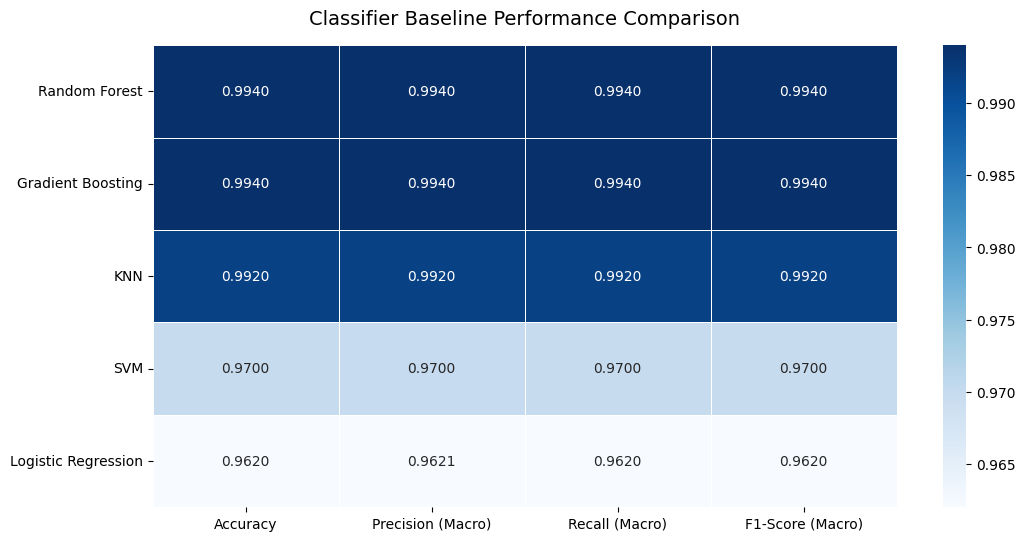

In [10]:
plt.figure(figsize=(12, 6))
sns.heatmap(df_comparison, annot=True, cmap="Blues", fmt=".4f", linewidths=.5)
plt.title("Classifier Baseline Performance Comparison", fontsize=14, pad=15)
plt.ylabel("")
plt.show()

### 6. Automated Hyperparameter Tuning (`GridSearchCV`)
Pick the top baseline algorithm (or manually choose one) to extract extra performance juice using Stratified Cross-Validation optimization.

In [11]:
best_model_name = "Random Forest" # Set to "auto" to select the best baseline model from the comparison matrix

if best_model_name == "auto":
    # Dynamically pick the best baseline model name based on highest F1-score
    best_model_name = df_comparison.index[0]
    print(f"Automatically selected model for hyperparameter tuning: {best_model_name}\n")
else:
    print(f"Manually selected model for hyperparameter tuning: {best_model_name}\n")
    

# Define parameters for exploration based on selection
if best_model_name == "Random Forest":
    estimator = RandomForestClassifier(random_state=42)
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10]
    }
elif best_model_name == "SVM":
    estimator = SVC(probability=True, random_state=42)
    param_grid = {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    }
elif best_model_name == "Gradient Boosting":
    estimator = HistGradientBoostingClassifier(random_state=42)
    param_grid = {
        'learning_rate': [0.01, 0.1, 0.2],
        'max_iter': [50, 100, 200],
        'max_depth': [3, 5, None]
    }
elif best_model_name == "Logistic Regression":
    estimator = LogisticRegression(max_iter=1000, random_state=42)
    param_grid = {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'saga']
    }
else: # Defaulting to KNN configuration
    estimator = KNeighborsClassifier()
    param_grid = {
        'n_neighbors': [3, 5, 11, 19],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }

# Run stratified k-fold cross validation configuration
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(estimator=estimator, param_grid=param_grid, cv=cv_strategy, scoring='f1_macro', n_jobs=-1)

print("🔄 Executing Grid Search... Please wait...")
grid_search.fit(X_train_scaled, y_train)

print("¼ Grid Search Optimization Complete!")
print(f"Best Hyperparameters Found: {grid_search.best_params_}")
print(f"Best Out-of-Fold Macro F1-Score: {grid_search.best_score_:.4f}")

Manually selected model for hyperparameter tuning: Random Forest

🔄 Executing Grid Search... Please wait...
¼ Grid Search Optimization Complete!
Best Hyperparameters Found: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best Out-of-Fold Macro F1-Score: 0.9860


### 7. Final Model Evaluation
Evaluate the finalized, tuned champion classifier against the held-out test dataset.

In [12]:
tuned_model = grid_search.best_estimator_
final_predictions = tuned_model.predict(X_test_scaled)

print(f"=== Final Performance Breakdown for Tuned {best_model_name} ===\n")
print(classification_report(y_test, final_predictions))

# save model
if os.path.exists(saved_model_path):
    print(f'saved_model_path, {saved_model_path}, already exists. Skipping.')
else:
    joblib.dump(tuned_model, saved_model_path, compress=3)
    print(f'model saved to {saved_model_path}')

=== Final Performance Breakdown for Tuned Random Forest ===

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       250
           1       1.00      0.99      0.99       250

    accuracy                           0.99       500
   macro avg       0.99      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500

saved_model_path, tree_shape_rf_model.joblib, already exists. Skipping.


### Retrain the Random Forest model without scaling, fine tune, and save in a file

In [13]:
def zulu_timestamp():
    return datetime.now(timezone.utc).strftime('%Y%m%dT%H%MZ')

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print('\nFine tuning:')
param_grid = {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5, 10]}
# Run stratified k-fold cross validation configuration
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(estimator=estimator, param_grid=param_grid, cv=cv_strategy, scoring='f1_macro', n_jobs=-1)

# print("Executing Grid Search... Please wait...")
grid_search.fit(X_train, y_train)
# print("Grid Search Optimization Complete!")
print(f"Best Hyperparameters Found: {grid_search.best_params_}")
print(f"Best Out-of-Fold Macro F1-Score: {grid_search.best_score_:.4f}")

# Save the optimized estimator
model_path = f'rf_tree_shape_model{zulu_timestamp()}.joblib'
joblib.dump(grid_search.best_estimator_, model_path, compress=2)
print(f'Tuned model saved to {model_path}')


Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       250
           1       1.00      0.99      0.99       250

    accuracy                           0.99       500
   macro avg       0.99      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500


Confusion Matrix:
 [[249   1]
 [  2 248]]

Fine tuning:
Best Hyperparameters Found: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best Out-of-Fold Macro F1-Score: 0.9860
Tuned model saved to rf_tree_shape_model20261103T0015Z.joblib


### Load model from disk use it for classifying X_test

In [14]:
# Load model form file
loaded_model = joblib.load(model_path)

# Use the model to classify the first 10 rows of log Hu moments in X_test
# test_data = X_test.iloc[0:10,]
test_data = X_test
probs = loaded_model.predict_proba(test_data)

test_data_with_probs = test_data.copy()
for i, class_label in enumerate(loaded_model.classes_):
    test_data_with_probs[f"prob_class_{class_label}"] = probs[:, i]
    # test_data_with_probs['tree_id'] = df.loc[test_data.index, 'tree_id'].values  # Add tree_id for reference
    test_data_with_probs.rename(columns={'prob_class_0': 'p_alive', 'prob_class_1': 'p_dead'}, inplace=True)
    test_data_with_probs['tree_class'] = [['alive', 'dead'][class_id] for class_id in y_test]
test_data_with_probs['tree_id'] = df.loc[test_data.index, 'tree_id'].values  # Add tree_id for reference
                                         
test_data_with_probs.head(10)

,h1,h2,h3,h4,h5,h6,h7,p_alive,tree_class,p_dead,tree_id
1370,-0.5642,-1.1254,-0.4354,-0.4284,-0.8603,-0.9876,2.5873,0.00,dead,1.00,308
654,0.5905,1.7683,1.9566,2.1481,4.2012,3.1149,-5.4433,1.00,alive,0.00,8767
1778,-0.3042,-0.6045,0.6228,0.6389,1.2697,0.3367,-4.3195,0.00,dead,1.00,18331
646,0.3555,1.0494,0.9799,1.1213,2.1727,1.6636,3.3941,1.00,alive,0.00,20615
1171,0.1250,0.2830,0.9366,1.0078,1.9799,1.1505,4.0521,0.08,dead,0.92,14011
484,0.7585,3.2763,3.1998,5.3423,-9.6366,7.1884,-10.1092,1.00,alive,0.00,23582
566,0.5247,1.4430,1.6249,1.9487,3.7376,2.6862,4.7412,1.00,alive,0.00,22793
1605,-0.3989,-0.7873,-0.3814,-0.3343,-0.6921,-0.7260,1.3190,0.00,dead,1.00,9421
839,0.6216,1.9476,2.7161,3.6812,6.8926,4.6647,7.5007,1.00,alive,0.00,11739
102,-0.0048,0.0200,0.4874,0.5441,1.0599,0.5546,3.5122,0.68,alive,0.32,10417


### Visualize classification results for first 10 rows of X_test

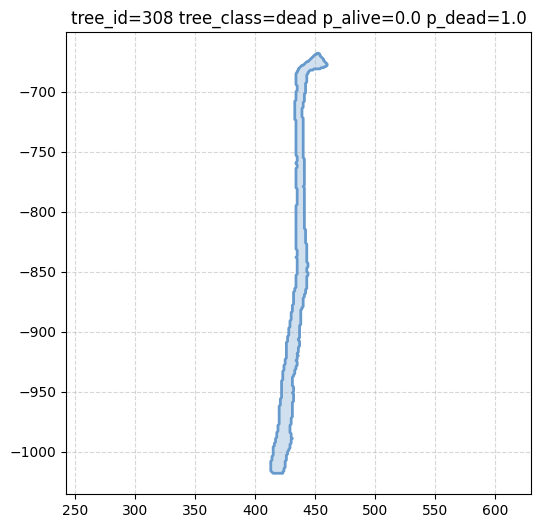

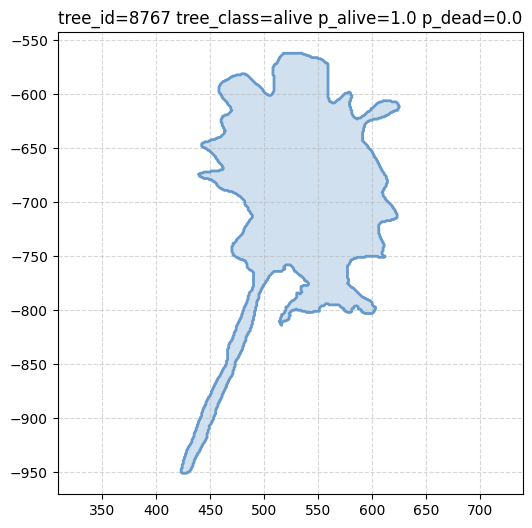

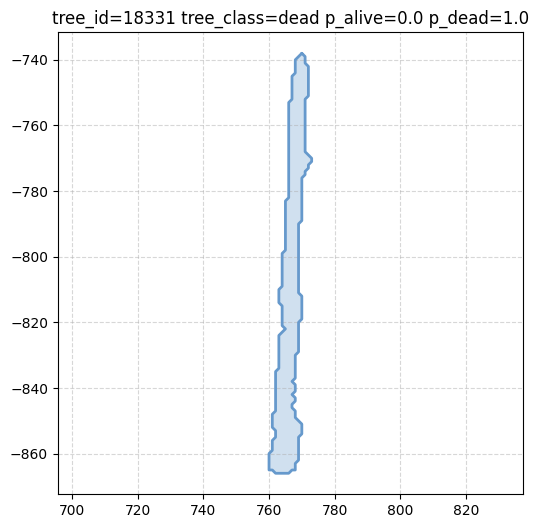

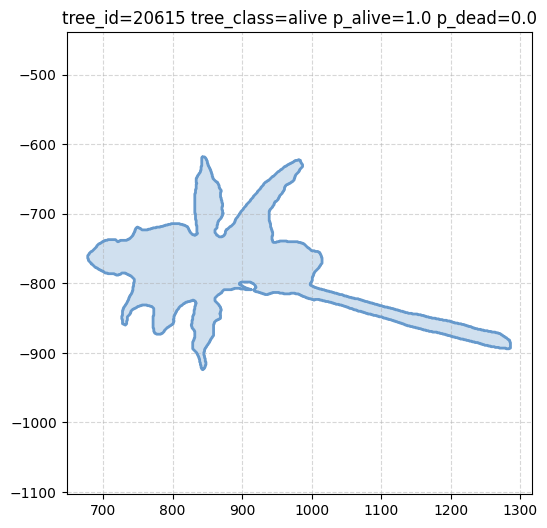

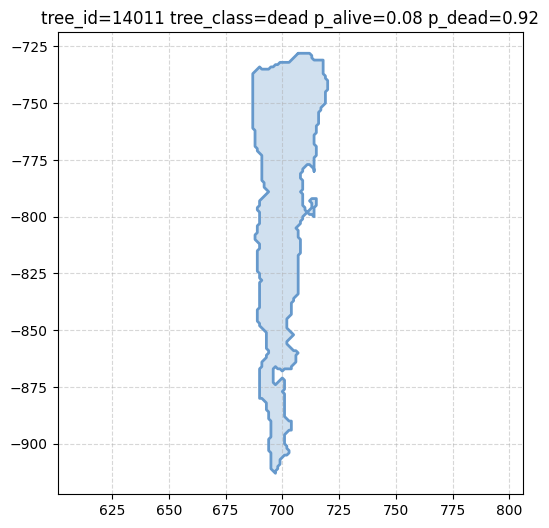

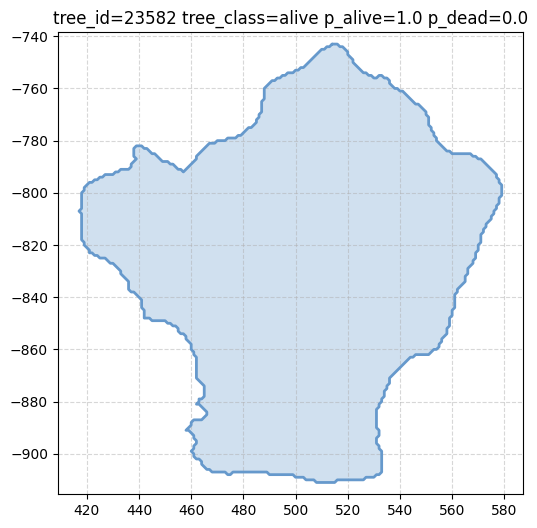

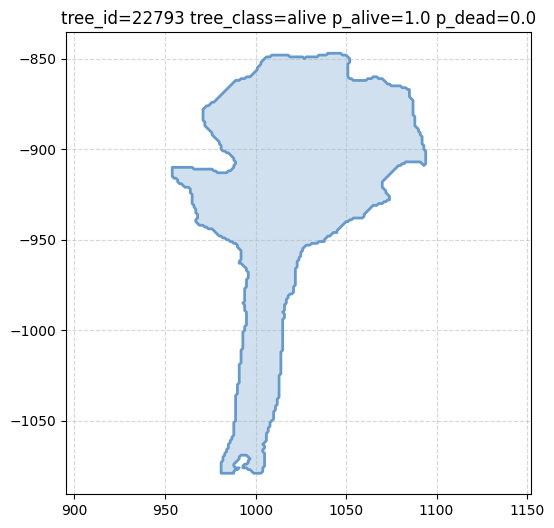

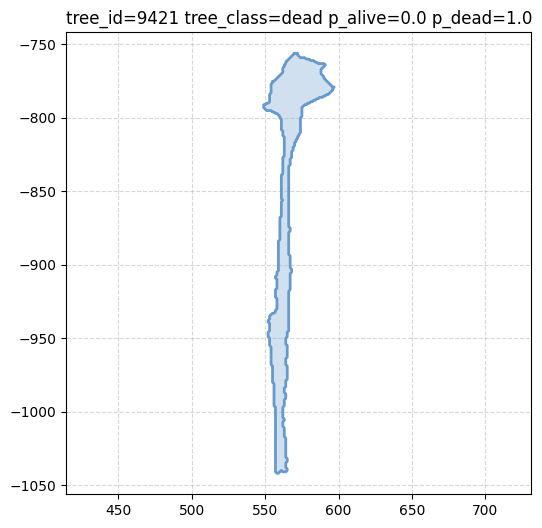

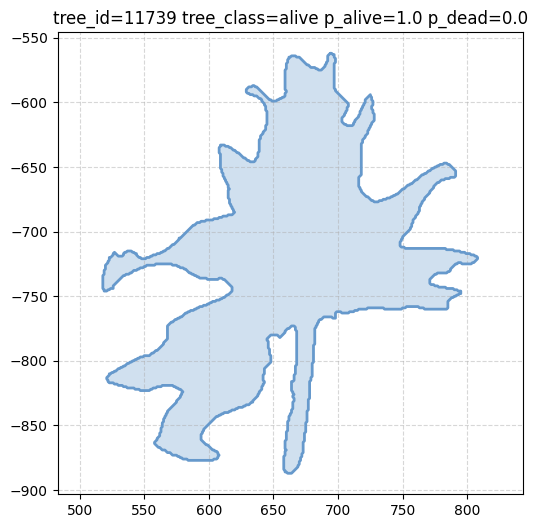

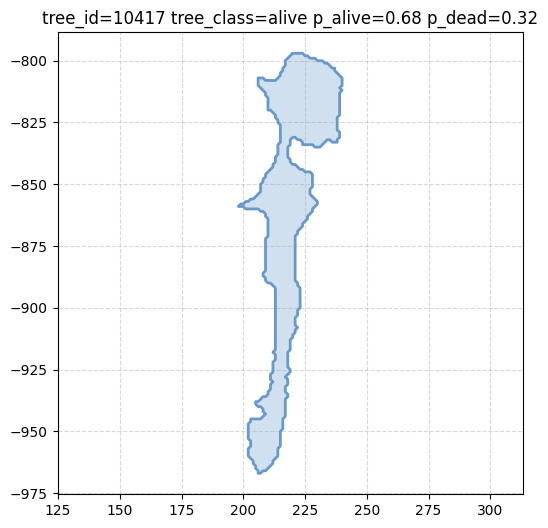

In [15]:
cursor = conn.cursor()
for i, r in test_data_with_probs.head(10).iterrows():
    tree_id, tree_class, p_alive, p_dead = r['tree_id'], r['tree_class'], r['p_alive'], r['p_dead']
    title = f'tree_id={tree_id} tree_class={tree_class} p_alive={p_alive} p_dead={p_dead}'
    sql = f'SELECT ST_AsText(tree_poly) FROM trees WHERE tree_id = {tree_id}'
    wkt_str = cursor.execute(sql).fetchone()[0]
    wkt_str_to_image(wkt_str, title, show_image=True)

### Results

Visualization uncovers obvious problems with the training dataset:

|   tree_id | tree_class   | comment|
|----------:|:-------------|--------|
|       308 | dead         |ok|
|      8767 | alive        |ok|
|     18331 | dead         |ok|
|     20615 | alive        |strange tree rotation|
|     14011 | dead         |strange shape|
|     23582 | alive        |strange shape|
|     22793 | alive        |ok|
|      9421 | dead         |misclassified as dead|
|     11739 | alive        |strange shape|
|     10417 | alive        |strange shape|
